# Lesson 6: Titanic survival

Explore passenger records from `data_tms.csv`. The `Survived` column is 1 for survivors and 0 for passengers who died. Run the cells from this folder with pandas, Matplotlib, and seaborn installed.

**Data:** [Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data). Download the labeled `train.csv`, rename it to `data_tms.csv`, and place it in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data_tms.csv')

print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


In [2]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [3]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Missing values

Count missing entries and drop rows with no recorded embarkation port. Extract the title from the name and use the median age for that title to fill missing ages. Use the overall median when a title has no recorded ages.

In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
df = df.dropna(subset=["Embarked"]).copy()

In [7]:
titles = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
titles = titles.replace({"Ms": "Miss"})
df["Title"] = titles.where(titles.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")

title_age_median = df.groupby("Title")["Age"].transform("median")
df["Age"] = df["Age"].fillna(title_age_median).fillna(df["Age"].median())

In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Title            0
dtype: int64

## Survival patterns

Compare passenger counts by outcome, sex, and ticket class. Counts reflect group sizes, so use proportions if you want to compare survival rates. The age plots include imputed ages.

In [9]:
df['Survived'].value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

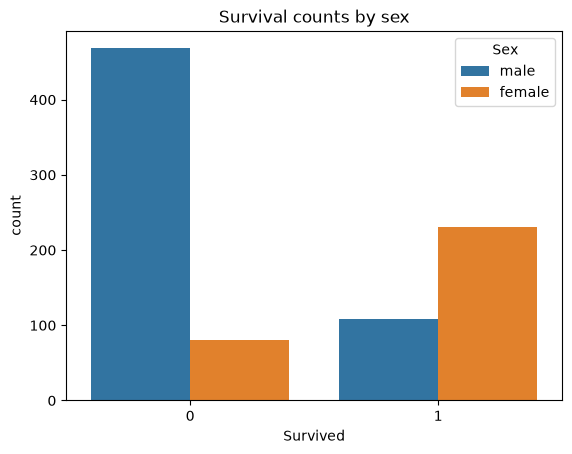

In [10]:
sns.countplot(x='Survived', hue='Sex', data=df)
plt.title('Survival counts by sex')
plt.show()

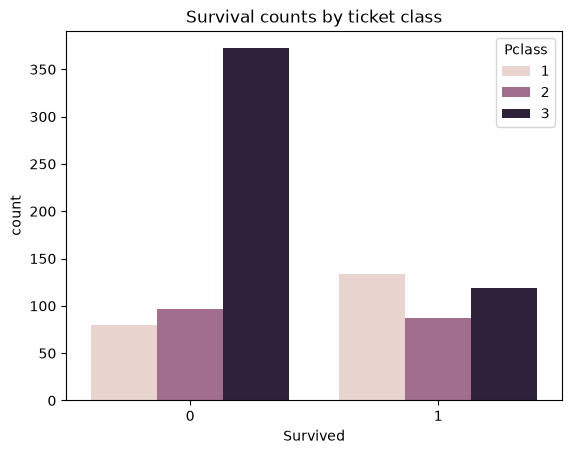

In [11]:
sns.countplot(x='Survived', hue='Pclass', data=df)
plt.title('Survival counts by ticket class')
plt.show()

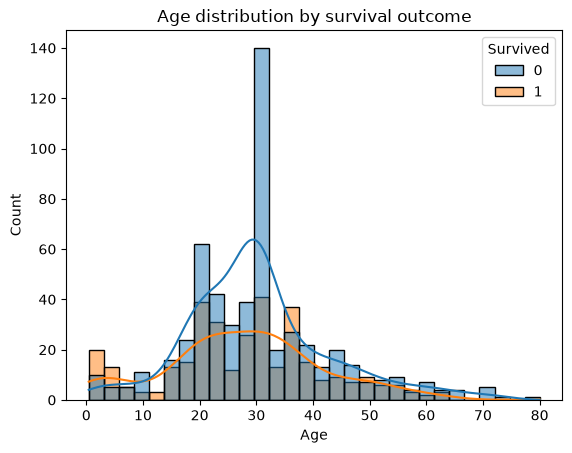

In [12]:
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30)
plt.title('Age distribution by survival outcome')
plt.show()

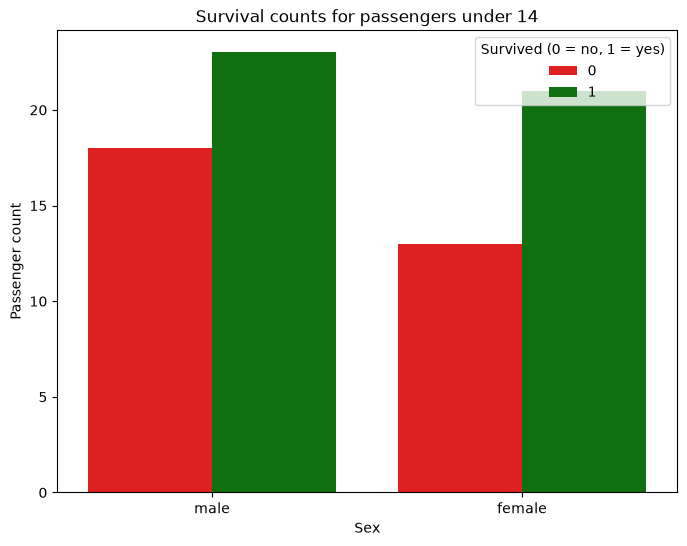

In [13]:
children = df[df['Age'] < 14]

plt.figure(figsize=(8,6))
sns.countplot(x='Sex', hue='Survived', data=children, palette={0:'red', 1:'green'})
plt.title('Survival counts for passengers under 14')
plt.xlabel("Sex")
plt.ylabel("Passenger count")
plt.legend(title="Survived (0 = no, 1 = yes)")
plt.show()

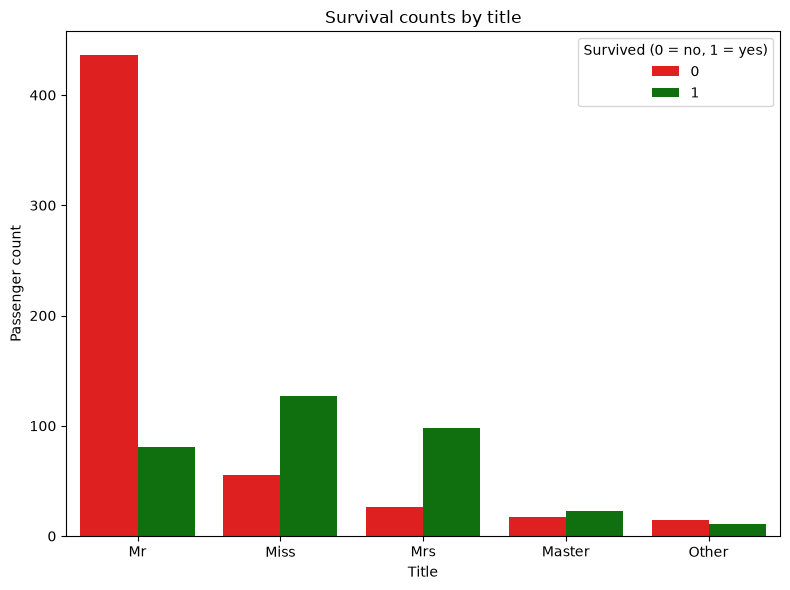

In [14]:
order_titles = df['Title'].value_counts().index

plt.figure(figsize=(8, 6))
sns.countplot(x='Title', hue='Survived', data=df, order=order_titles, palette={0: 'red', 1: 'green'})
plt.title('Survival counts by title')
plt.xlabel("Title")
plt.ylabel("Passenger count")
plt.legend(title="Survived (0 = no, 1 = yes)")
plt.tight_layout()
plt.show()

## Age range by title

The minimum and maximum show the spread within each title group.

In [15]:
df.groupby("Title")["Age"].agg(["min", "max"])

,min,max
Title,,
Master,0.42,12.0
Miss,0.75,63.0
Mr,11.00,80.0
Mrs,14.00,63.0
Other,23.00,70.0


## Features from names

Extract any text in parentheses and assign a code to each normalized surname. `FamilyID` groups matching surnames and can put unrelated passengers in the same group.

In [16]:
df["Name_in_parentheses"] = (
    df["Name"]
    .str.extract(r"\(([^)]+)\)", expand=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df[["Name", "Name_in_parentheses"]].head(10)

,Name,Name_in_parentheses
0,"Braund, Mr. Owen Harris",NaN
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Florence Briggs Thayer
2,"Heikkinen, Miss. Laina",NaN
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Lily May Peel
4,"Allen, Mr. William Henry",NaN
5,"Moran, Mr. James",NaN
6,"McCarthy, Mr. Timothy J",NaN
7,"Palsson, Master. Gosta Leonard",NaN
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Elisabeth Vilhelmina Berg
9,"Nasser, Mrs. Nicholas (Adele Achem)",Adele Achem


In [17]:
def add_surname_features(df: pd.DataFrame) -> pd.DataFrame:
    if 'Name' not in df.columns:
        raise KeyError("Ожидается столбец 'Name' в DataFrame, но он не найден.")
    out = df.copy()

    name = out['Name'].astype('string')
    out['Surname'] = (
        name
        .str.split(',', n=1)
        .str[0]
        .str.strip()
    )


    surname_norm = (
        out['Surname']
        .astype('string')
        .str.lower()
        .str.replace(r'[^a-z]', '', regex=True)
    )


    codes, _ = pd.factorize(surname_norm, sort=True)
    out['FamilyID'] = pd.Series(codes, index=out.index).where(codes >= 0,  -1) + 1
    out['FamilyID'] = out['FamilyID'].where(surname_norm.notna(), 0)

    return out

df = add_surname_features(df)

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Name_in_parentheses,Surname,FamilyID
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,NaN,Braund,74
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,Florence Briggs Thayer,Cumings,137
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,NaN,Heikkinen,256
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,Lily May Peel,Futrelle,203
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,NaN,Allen,12
5,6,0,3,"Moran, Mr. James",male,30.0,0,0,330877,8.4583,NaN,Q,Mr,NaN,Moran,413
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,Mr,NaN,McCarthy,382
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,Master,NaN,Palsson,467
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,Mrs,Elisabeth Vilhelmina Berg,Johnson,296
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,Mrs,Adele Achem,Nasser,430


## A rule-based prediction

Apply hand-written rules based on sex, ticket class, age, fare, and the number of relatives on board. The example gives a prediction for one passenger. A single example cannot measure how well the rules generalize.

In [18]:
def predict_survival(passenger: dict) -> int:
    defaults = {'Sex': '', 'Pclass': 3, 'Age': 30.0, 'SibSp': 0, 'Parch': 0, 'Fare': 15.0}
    d = {**defaults, **passenger}
    sex   = str(d['Sex']).lower()
    pclass= int(d['Pclass'])
    age   = float(d['Age'])
    sibsp = int(d['SibSp'])
    parch = int(d['Parch'])
    fare  = float(d['Fare'])
    fam   = sibsp + parch


    if sex == 'female':
        if pclass == 3:
            if age >= 40:
                return 0
            else:
                if fam >= 3:
                    return 0
                else:
                    return 1
        else:
            return 1
    else:
        if age < 12:
            return 1
        if pclass == 1 and fare >= 50:
            return 1
        if age < 18 and fam >= 2:
            return 1
        return 0

passenger = {
    "PassengerId": 161,
    "Survived": 0,
    "Pclass": 3,
    "Name": "Cribb, Mr. John Hatfield",
    "Sex": "male",
    "Age": 44,
    "SibSp": 0,
    "Parch": 1,
    "Ticket": "371362",
    "Fare": 16.1,
    "Cabin": None,
    "Embarked": "S"
}

pred = predict_survival(passenger)
print("Predicted outcome:", "Survived" if pred == 1 else "Did not survive")

Predicted outcome: Did not survive
